# 03 - Exploratory Data Analysis

Using the cleaned data. I look at seasonality, yield by crop and district, how rain relates to yield, and prices.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../dataset/cleaned_dataset.csv')
season = df.drop_duplicates(['taluka', 'crop', 'season_year']).copy()
print(len(df), 'rows,', len(season), 'seasons')
season.groupby('crop').yield_q_ha.describe().round(1)

347760 rows, 7560 seasons
          count  mean  std   min   25%   50%   75%   max
crop                                                    
cotton   1512.0   6.3  1.2   2.5   5.5   6.4   7.1   9.8
gram     1512.0  11.9  2.3   4.9  10.4  12.0  13.4  17.9
soybean  1512.0  11.5  2.0   4.8  10.1  11.5  12.9  18.1
tur      1512.0   7.7  1.4   3.3   6.8   7.7   8.7  12.8
wheat    1512.0  28.6  6.4  11.3  23.8  28.9  33.5  45.1


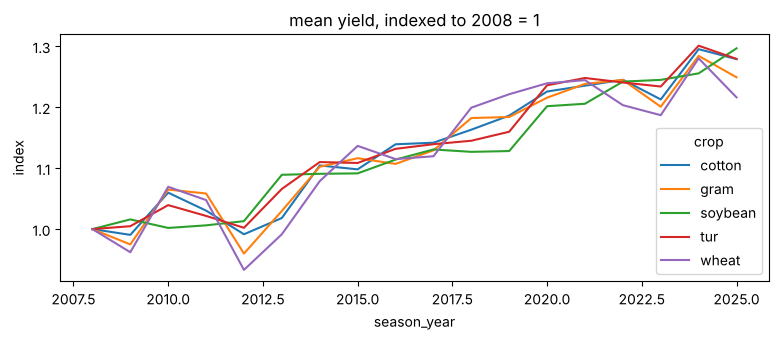

In [2]:
# yield trend per crop
tr = season.groupby(['season_year', 'crop']).yield_q_ha.mean().unstack()
(tr / tr.iloc[0]).plot(figsize=(8, 3.5), title='mean yield, indexed to 2008 = 1')
plt.ylabel('index')
plt.tight_layout()
plt.savefig('../reports/figures/03_yield_trend.png', dpi=120)

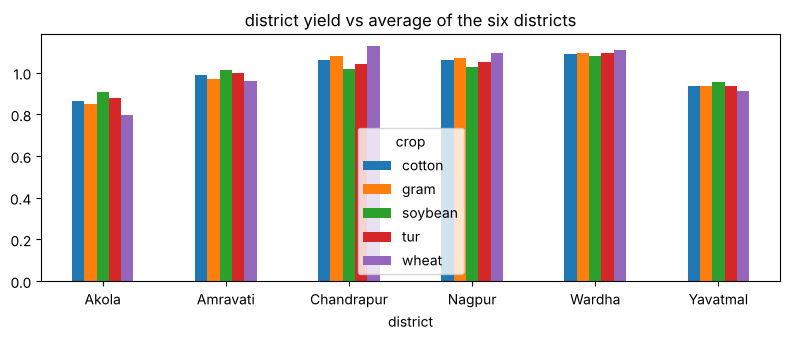

In [3]:
# yield by district (relative to the all-district average of that crop)
dd = season.groupby(['district', 'crop']).yield_q_ha.mean().unstack()
(dd / dd.mean()).plot.bar(figsize=(8, 3.5), title='district yield vs average of the six districts')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../reports/figures/03_yield_by_district.png', dpi=120)

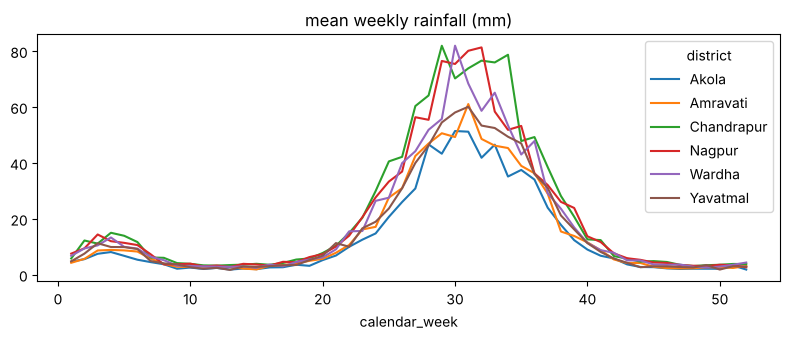

In [4]:
# rainfall over the calendar year
st = df.drop_duplicates(['taluka', 'abs_week'])
st.groupby(['calendar_week', 'district']).rain_mm.mean().unstack().plot(figsize=(8, 3.5), title='mean weekly rainfall (mm)')
plt.tight_layout()
plt.savefig('../reports/figures/03_rainfall_seasonality.png', dpi=120)

Rain is almost all in weeks 23-40. Kharif crops (soybean, cotton, tur) live on it directly. Rabi crops (wheat, gram) depend on soil moisture left from the monsoon plus irrigation.

crop
cotton     0.26
gram       0.23
soybean   -0.13
tur        0.08
wheat      0.41
dtype: float64


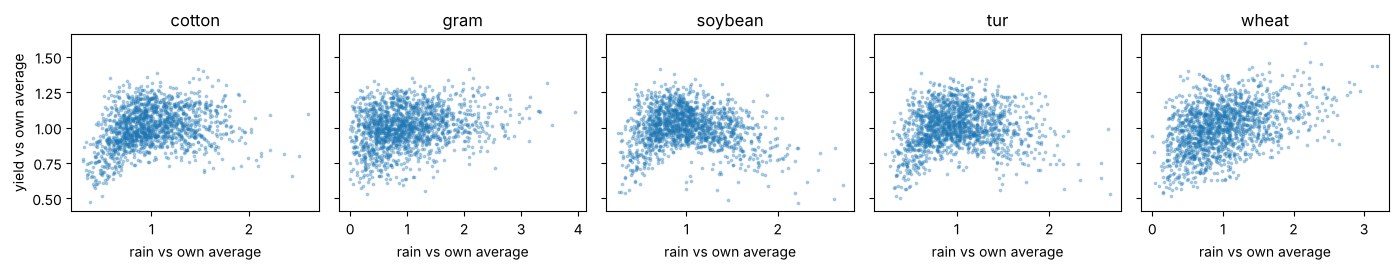

In [5]:
# season rain (growing window) vs yield, relative to each taluka-crop's own average
win = df[(df.season_week >= 2) & (df.season_week <= df.crop.map({'soybean': 15, 'cotton': 27, 'tur': 25, 'wheat': 14, 'gram': 12}))]
rain_total = win.groupby(['taluka', 'crop', 'season_year']).rain_mm.sum().rename('season_rain')
s = season.join(rain_total, on=['taluka', 'crop', 'season_year'])
s['rel_yield'] = s.yield_q_ha / s.groupby(['taluka', 'crop']).yield_q_ha.transform('mean')
s['rel_rain'] = s.season_rain / s.groupby(['taluka', 'crop']).season_rain.transform('mean')

fig, ax = plt.subplots(1, 5, figsize=(14, 2.8), sharey=True)
for a, (c, d) in zip(ax, s.groupby('crop')):
    a.scatter(d.rel_rain, d.rel_yield, s=3, alpha=0.3)
    a.set_title(c)
    a.set_xlabel('rain vs own average')
ax[0].set_ylabel('yield vs own average')
plt.tight_layout()
plt.savefig('../reports/figures/03_rain_vs_yield.png', dpi=120)
print(s.groupby('crop').apply(lambda d: d.rel_rain.corr(d.rel_yield)).round(2))

The straight-line link is weak (correlation between about -0.1 and 0.4 depending on the crop). That is expected: in a normal monsoon rain is more than the crop needs, so extra rain adds nothing, and only dry or badly spread seasons hurt. So I should not rely on a linear model for this; rain compared with normal, and dry spells, are better candidates for tree models.

In [6]:
# irrigation and soil
s['irr_band'] = pd.cut(s.irrigated_share, [0, .2, .3, .4, 1])
print(s.groupby('irr_band').rel_yield.std().round(3).rename('yield swing by irrigation band'))
s.groupby('crop')[['soil_N', 'soil_OC', 'soil_pH', 'irrigated_share']].corrwith(s.rel_yield)

irr_band
(0.0, 0.2]    0.148
(0.2, 0.3]    0.155
(0.3, 0.4]    0.130
(0.4, 1.0]    0.125
Name: yield swing by irrigation band, dtype: float64
           soil_N   soil_OC   soil_pH  irrigated_share
crop                                                  
cotton   0.020635  0.007043  0.004822         0.187315
gram     0.024308  0.009725  0.001322         0.185155
soybean  0.021928  0.008232 -0.000940         0.186181
tur      0.019712  0.008643  0.003815         0.213055
wheat    0.020885  0.004885  0.002135         0.181586


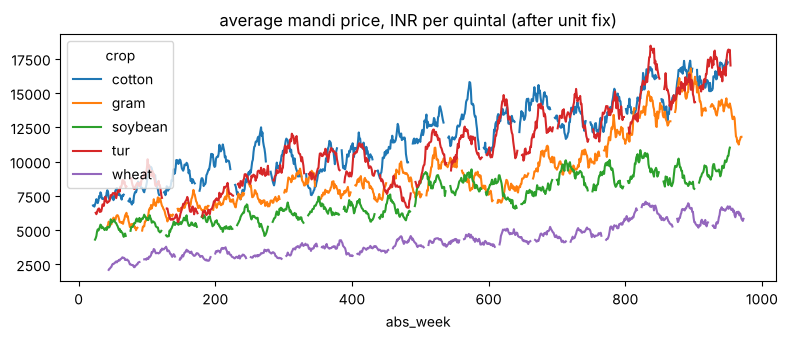

In [7]:
# prices
p = df.groupby(['abs_week', 'crop']).price_q.mean().unstack()
p.plot(figsize=(8, 3.5), title='average mandi price, INR per quintal (after unit fix)')
plt.tight_layout()
plt.savefig('../reports/figures/03_prices.png', dpi=120)

In [8]:
# how much does last year's yield tell us about this year's?
s = s.sort_values(['taluka', 'crop', 'season_year'])
s['last_year'] = s.groupby(['taluka', 'crop']).yield_q_ha.shift(1)
print(s.groupby('crop').apply(lambda d: d.yield_q_ha.corr(d.last_year)).round(2))

crop
cotton     0.61
gram       0.63
soybean    0.59
tur        0.59
wheat      0.60
dtype: float64


## What I take from the EDA

- Yield level is mostly taluka and crop specific, so history (last seasons' yield) will be a strong feature and also the natural baseline.
- Deviations from the normal level are driven by rain so far compared with normal, dry spells, heat in the rabi season, irrigation and soil.
- Prices move on their own cycle; they are weak predictors of yield but matter for procurement decisions.
- Yield trends up about 1.5% a year, so a 3-year average baseline will lag slightly.

Next: 04_Feature_Engineering.